John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
# library(ranger) # engine for random forest

# set random seed
set.seed(42)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.5.2
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.0 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() mask

Load data

In [2]:
data <- read_csv("../data/matching_opportunities.csv")

Rows: 709 Columns: 82
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (81): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# Model Inputs
model_columns <- c(
        "UST", 
        # "does_it_match",
        # "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        "M1_1_last_UST", "M2_1_last_UST", "M3_1_last_UST", "M4_1_last_UST", "M5_1_last_UST", "M6_1_last_UST", # TODO: These are categorical variables, how does this implementation of knn handle those?
        # "time_M1_last_song", "time_M2_last_song", "time_M3_last_song", "time_M4_last_song", "time_M5_last_song", "time_M6_last_song",
    	"time_since_M1_1_last_song", "time_since_M2_1_last_song", "time_since_M3_1_last_song", "time_since_M4_1_last_song", "time_since_M5_1_last_song", "time_since_M6_1_last_song"
        # "time_rel_sunrise"
    )

In [4]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(model_columns) %>%
    drop_na() # drop any row containing at least one NA value

Warning message:
“Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(model_columns)

  # Now:
  data %>% select(all_of(model_columns))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”


In [5]:
glimpse(data)

Rows: 428
Columns: 13
$ UST                       <fct> 20, 3, 0, 13, 29, 9, 8, 3, 116, 29, 10, 8, 3…
$ M1_1_last_UST             <fct> 0, 0, 3, 0, 8, 29, 9, 8, 3, 116, 29, 10, 8, …
$ M2_1_last_UST             <fct> 0, 8, 9, 0, 0, 5, 16, 9, 3, 8, 8, 9, 3, 9, 1…
$ M3_1_last_UST             <fct> 0, 8, 0, 0, 9, 8, 8, 0, 0, 0, 8, 9, 3, 0, 16…
$ M4_1_last_UST             <fct> 0, 9, 9, 0, 9, 3, 3, 8, 8, 9, 9, 10, 10, 3, …
$ M5_1_last_UST             <fct> 0, 8, 0, 0, 0, 0, 8, 0, 0, 10, 10, 8, 8, 20,…
$ M6_1_last_UST             <fct> 0, 0, 0, 0, 8, 8, 0, 0, 0, 0, 0, 0, 3, 0, 0,…
$ time_since_M1_1_last_song <dbl> 5.890881, 43.989810, 14.397677, 55.771537, 8…
$ time_since_M2_1_last_song <dbl> 9.8429906, 5.8120005, 5.5579771, 5.1593139, …
$ time_since_M3_1_last_song <dbl> 6.117981, 7.213702, 8.059989, 4.721791, 8.57…
$ time_since_M4_1_last_song <dbl> 2.010357, 8.070434, 5.797139, 4.745750, 9.39…
$ time_since_M5_1_last_song <dbl> 5.75153467, 3.51400991, 0.08138158, 9.151744…
$ time_since_M6_1_

In [6]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=UST)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many of each song type?
n_ust <- train_data %>%
    group_by(UST) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data)) %>%
    arrange(percent)
n_ust

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = UST)

UST,n,percent
<fct>,<int>,<dbl>
16,1,0.3367003
118,1,0.3367003
119,1,0.3367003
12,2,0.6734007
116,2,0.6734007
117,2,0.6734007
0,4,1.3468013
5,16,5.3872054
17,20,6.7340067


In [7]:
# Data preprocessing using a recipe
recipe <- recipe(UST ~ ., data = train_data) %>%
    step_scale(all_numeric()) %>% # scale all numeric predictors
    step_center(all_numeric()) # center all numeric predictors

In [8]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

In [9]:
tune_grid <- tidyr::crossing(
    mtry = c(4, 8, 12, 16, 20), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

model_tuning

→ A | warning: Dropped unused factor level(s) in dependent variable: 20, 115, 118, 120.

There were issues with some computations   A: x1

There were issues with some computations   A: x10

There were issues with some computations   A: x28

There were issues with some computations   A: x66

There were issues with some computations   A: x105

→ B | warning: ! 16 columns were requested but there were 12 predictors in the data.
               ℹ 12 predictors will be used.

There were issues with some computations   A: x105
There were issues with some computations   A: x136   B: x1

There were issues with some computations   A: x190   B: x10

→ C | warning: ! 20 columns were requested but there were 12 predictors in the data.
               ℹ 12 predictors will be used.

There were issues with some computations   A: x190   B: x10
There were issues with some computations   A: x253   B: x25   C: x3

There were issues with some computations   A: x300   B: x35   C: x10

→ D | warning: While co

In [10]:
# Accuracies listed use 5-fold cross validation 2025-10-17
model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
model_tuning_accuracies

mtry,min_n,.metric,.estimator,mean,n,std_err,.config
<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
4,2,accuracy,multiclass,0.2048882,5,0.02407085,pre0_mod01_post0
4,5,accuracy,multiclass,0.2113909,5,0.02936788,pre0_mod02_post0
4,10,accuracy,multiclass,0.1748164,5,0.02585981,pre0_mod03_post0
4,15,accuracy,multiclass,0.1954028,5,0.03223179,pre0_mod04_post0
4,20,accuracy,multiclass,0.1782100,5,0.03445279,pre0_mod05_post0
8,2,accuracy,multiclass,0.1917246,5,0.02383827,pre0_mod06_post0
8,5,accuracy,multiclass,0.2017906,5,0.03618768,pre0_mod07_post0
8,10,accuracy,multiclass,0.2012096,5,0.03267744,pre0_mod08_post0
8,15,accuracy,multiclass,0.1949975,5,0.03134828,pre0_mod09_post0


Ignoring unknown labels:
• colour : "Estimated Accuracy"


[1] "Best hyperparameters: (mtry, min_n)"
10 
 8 


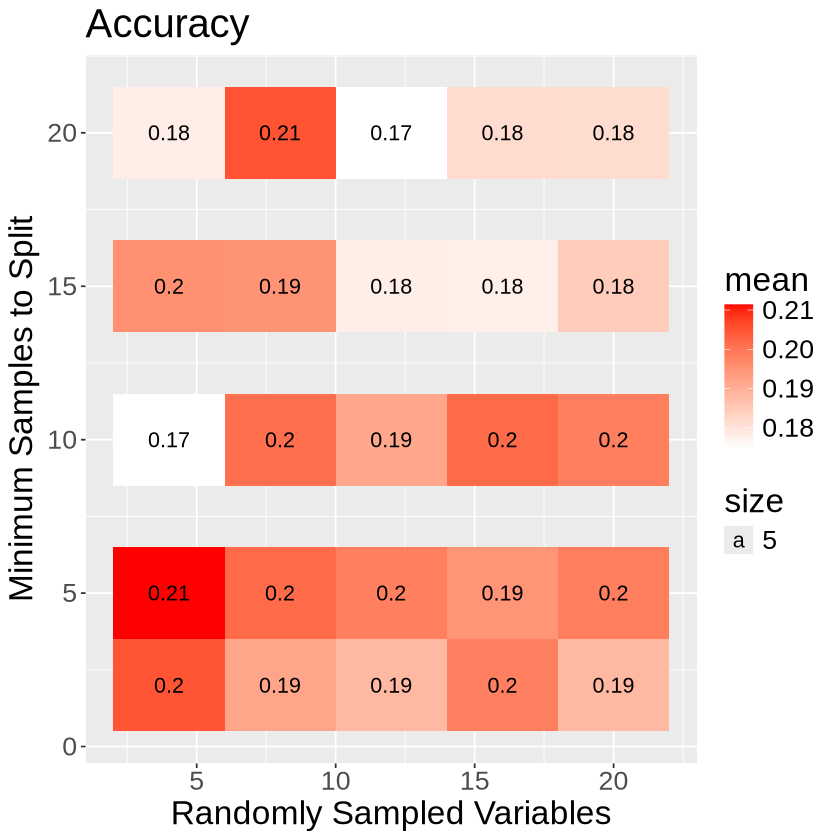

In [11]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters: (mtry, min_n)")
print(best_params)

Ignoring unknown labels:
• colour : "Estimated Recall"


[1] "Best hyperparameters:"
10 
 8 


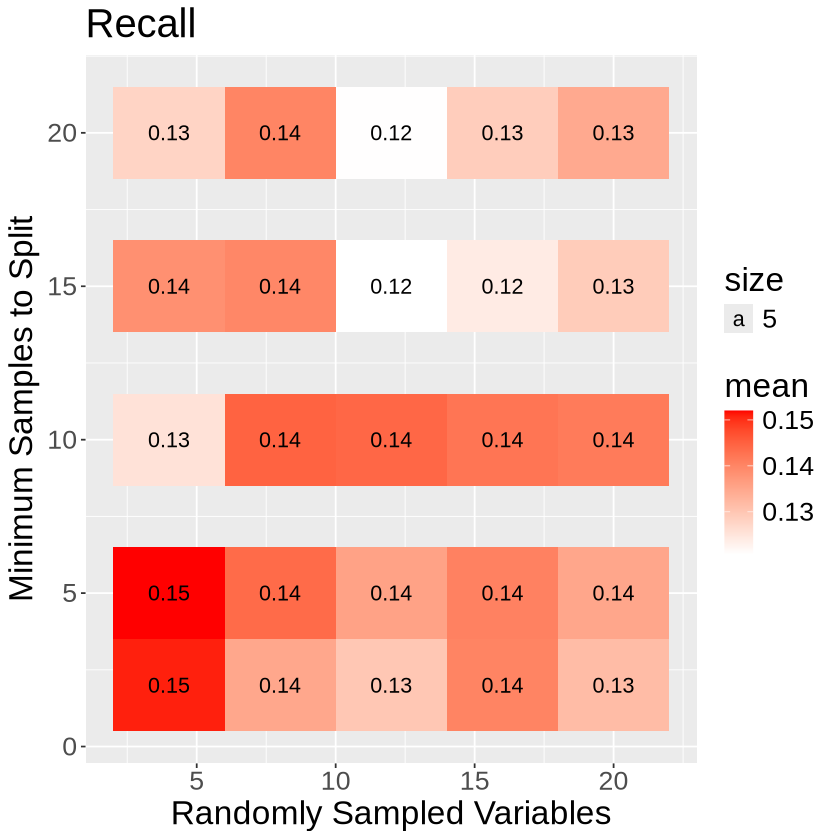

In [12]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies %>% filter(.metric == "recall")) +
    geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
    geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Recall", title="Recall") +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
print("Best hyperparameters:")
print(best_params)

In [13]:
# retrain model on best parameters
best_params <- model_tuning %>%
  select_best()
print("Best Parameters:")
print(best_params)

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%
    finalize_workflow(best_params) %>%
    # fit_resamples(resamples = train_vfold) # for v-fold cross validation
    fit(data = train_data) # to train on whole train set with no validation set

model

Warning message in select_best(.):
“No value of `metric` was given; "accuracy" will be used.”


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1     4     5 pre0_mod02_post0


Warning message:
“Dropped unused factor level(s) in dependent variable: 20, 115, 120.”


══ Workflow [trained] ══════════════════════════════════════════════════════════
Preprocessor: Recipe
Model: rand_forest()

── Preprocessor ────────────────────────────────────────────────────────────────
2 Recipe Steps

• step_scale()
• step_center()

── Model ───────────────────────────────────────────────────────────────────────
Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, mtry = min_cols(~4,      x), num.trees = ~1000, min.node.size = min_rows(~5, x), importance = ~"impurity",      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  1000 
Sample size:                      297 
Number of independent variables:  12 
Mtry:                             4 
Target node size:                 5 
Variable importance mode:         impurity 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.7604979 

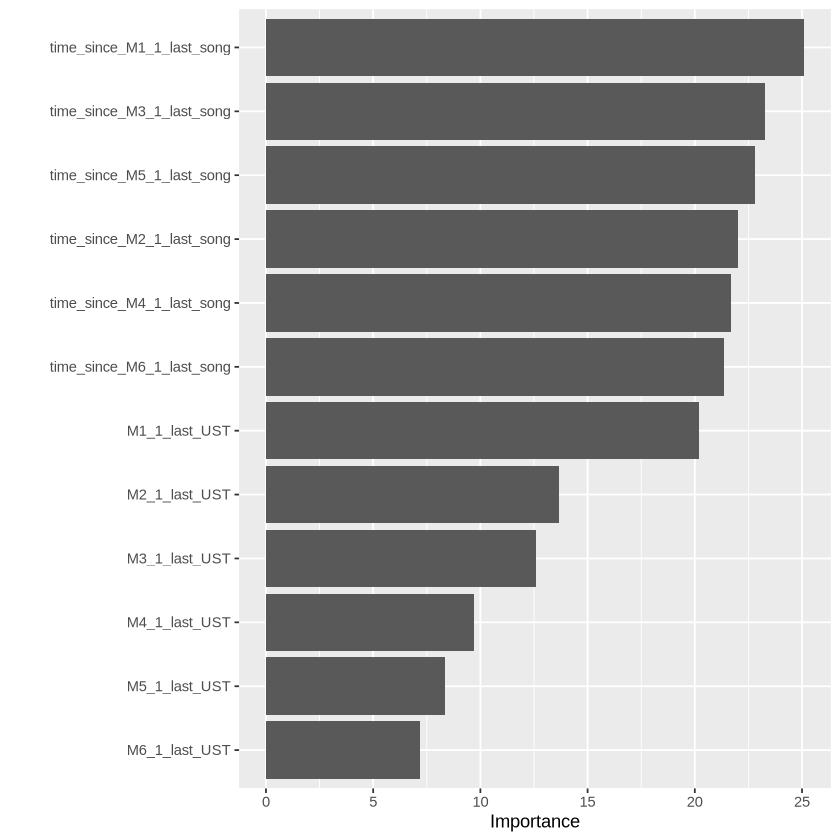

In [14]:
model %>% extract_fit_engine() %>% vip(num_features=50)

In [15]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% predict(test_data) %>%
    bind_cols(test_data)

In [16]:
# test_predictions

In [24]:
# What was the accuracy, precision, and recall of our model?
test_accuracy <- test_predictions %>% metrics(truth = UST, estimate = .pred_class) %>% filter(.metric == "accuracy")
test_accuracy

test_predictions %>% group_by(UST) %>% metrics(truth = UST, estimate = .pred_class) %>% filter(.metric == "accuracy") %>% arrange(desc(.estimate)) %>% 
    select(UST, .estimate) %>% rename(estimated_accuracy = .estimate) %>%
    left_join(n_ust %>% select(UST, n), by = "UST") 

test_predictions %>% group_by(UST) %>% precision(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate)) # Precision = correct positive predictions / total positive predictions
test_predictions %>% group_by(UST) %>% recall(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate)) # Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.1679389


ERROR: [1m[33mError[39m in `auto_copy()`:[22m
[1m[22m[33m![39m `x` and `y` must share the same src.
[36mℹ[39m `x` is a <tbl_df/tbl/data.frame> object.
[36mℹ[39m `y` is an integer vector.
[36mℹ[39m Set `copy = TRUE` if `y` can be copied to the same source as `x` (may be
  slow).


In [18]:
# test_predictions %>% pull(does_it_match) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
confusion_matrix

          Truth
Prediction 0 3 5 8 9 10 12 13 16 17 20 21 29 115 116 117 118 119 120
       0   0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       3   1 7 3 4 6  2  0  2  0  1  0  2  6   0   0   1   0   0   0
       5   0 1 1 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       8   0 2 0 5 4  4  0  0  0  1  1  0  4   0   1   0   0   0   0
       9   0 6 4 3 4  4  0  0  0  3  0  0  1   0   0   1   0   0   0
       10  0 2 0 1 1  1  0  1  0  1  0  2  1   0   0   0   0   0   0
       12  0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       13  0 0 0 0 1  1  0  0  0  0  0  1  0   0   0   0   0   0   0
       16  0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       17  0 0 0 2 0  0  0  0  0  0  0  0  1   0   0   0   0   0   0
       20  0 0 0 0 0  0  0  0  0  0  0  0  0   0   0   0   0   0   0
       21  0 0 1 0 0  2  0  2  0  2  0  1  0   0   0   0   0   0   0
       29  0 0 2 4 4  2  0  1  0  1  0  5  3   0   0   0   0   0   0
       115 0 0 0 0